# Klasterisasi Hierarki HDBSCAN — Metrik Euclidean

Notebook 1 dari 3 notebook metrik (Euclidean · Cosine · Manhattan) + 1 notebook
perbandingan. Dataset: RumahPoint (`properti_multi_kota.csv`), **disampel acak
15.000 baris** (benih 42 — sama di semua notebook sehingga hasilnya dapat
dibandingkan). Metode: HDBSCAN dengan metrik jarak **Euclidean**, lalu pohon
hierarkinya dipotong sampai **tepat 3 klaster** (kesepakatan kelompok).

**Jarak Euclidean** = panjang garis lurus antar titik (akar kuadrat jumlah selisih
kuadrat tiap kolom). Ia paling sensitif terhadap selisih besar pada satu kolom —
harga selisih miliaran menarik titik sangat jauh, sehingga klaster cenderung
memisahkan properti dari BESARNYA nilai.

## 1. Persiapan: pustaka, fungsi gambar, dan alat potong hierarki

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import hdbscan


def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    """Versi tervektoris dari fungsi visualisasi modul JS05."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 6))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    for k, col in zip(unique_labels, colors):
        mask = labels == k
        if k == -1:
            ax.scatter(X[mask, 0], X[mask, 1], marker="x", c="black", s=12, label="noise")
        else:
            ax.scatter(X[mask, 0], X[mask, 1], marker="o",
                       s=1 + 5 * probabilities[mask],
                       facecolor=tuple(col), edgecolor="k", linewidths=0.15)
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise_ = int((labels == -1).sum())
    preamble = "Sesungguhnya" if ground_truth else "Perkiraan"
    title = f"{preamble} jumlah klaster: {n_clusters_} | noise: {n_noise_}"
    if parameters is not None:
        params_str = ", ".join(f"{a}={b}" for a, b in parameters.items())
        title += f" | {params_str}"
    ax.set_title(title)
    plt.tight_layout()


def parse_pohon(tree, n):
    """Baca pohon terkondensasi: kelahiran cabang, anak, dan anggota poin."""
    born = tree[tree["child"] >= n]
    ROOT = int(born["parent"].mode().iloc[0])
    lahir, anak, poin = {}, {}, {}
    for p, c, v, cs in tree.itertuples(index=False):
        p, c = int(p), int(c)
        if c >= n:
            lahir[c] = float(v)
            if c != p:
                anak.setdefault(p, set()).add(c)
        elif p >= n:
            poin.setdefault(p, []).append(c)
    return ROOT, lahir, {k: list(v) for k, v in anak.items()}, poin


def cabang_aktif(anak, lahir, ROOT, t):
    out = []

    def rekursif(c):
        sub = [x for x in anak.get(c, []) if lahir[x] <= t]
        if sub:
            for x in sub:
                rekursif(x)
        elif c != ROOT:
            out.append(c)

    rekursif(ROOT)
    return out


def potong3(ROOT, lahir, anak, poin, n):
    """Potong hierarki pada ketinggian yang menghasilkan tepat 3 cabang."""
    waktu = sorted(set(lahir.values()))
    kandidat = [t for t in waktu if len(cabang_aktif(anak, lahir, ROOT, t)) == 3]
    assert kandidat, "tidak ada ketinggian yang menghasilkan tepat 3 cabang"
    t = kandidat[len(kandidat) // 2]
    memo = {}

    def anggota(c):
        if c in memo:
            return memo[c]
        m = list(poin.get(c, []))
        for x in anak.get(c, []):
            m += anggota(x)
        memo[c] = m
        return m

    sel = sorted(cabang_aktif(anak, lahir, ROOT, t), key=lambda c: -len(anggota(c)))
    lab = np.full(n, -1)
    for i, c in enumerate(sel):
        lab[anggota(c)] = i
    return t, lab, sel, anggota


## 2. Data: praproses lalu sampel 15.000 baris

Fitur yang dipakai (5 kolom, sama di semua notebook): `luas_m2`,
`luas_bangunan`, `jumlah_kamar`, `jumlah_kamar_mandi`, `log10(harga)`.
Nilai kosong luas bangunan ditebus median; `usia_bangunan` tidak ikut dihitung
(hanya kolom diagnosa, isinya 7,4% dan cacat).

In [2]:
CSVPAT = r"D:\Kuliah\Semester 5\Project\PBL\2026-2027 Ganjil\RumahPoint\dataset\properti_multi_kota.csv"

df = pd.read_csv(CSVPAT)
for c in ["luas_m2", "luas_bangunan", "jumlah_kamar", "jumlah_kamar_mandi",
          "usia_bangunan", "harga"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
d_full = df[(df["harga"] > 0) & (df["luas_m2"] > 0)].copy()

FITUR = ["luas_m2", "luas_bangunan", "jumlah_kamar", "jumlah_kamar_mandi"]
for c in FITUR:
    d_full[c] = d_full[c].fillna(d_full[c].median())
d_full["log_harga"] = np.log10(d_full["harga"])

s = d_full.sample(15000, random_state=42).copy()
X = StandardScaler().fit_transform(s[FITUR + ["log_harga"]])
Y = PCA(n_components=2, random_state=0).fit_transform(X)
n = len(X)
print("Baris union terpakai :", len(d_full))
print("Sampel notebook ini  :", n, "(random_state=42, sama di semua notebook metrik)")
print("Matriks fitur        :", X.shape)
ev = PCA(n_components=2, random_state=0).fit(X).explained_variance_ratio_.sum()
print("PCA 2D menahan", round(ev * 100, 1), "persen ragam (hanya untuk gambar)")


Baris union terpakai : 64650
Sampel notebook ini  : 15000 (random_state=42, sama di semua notebook metrik)
Matriks fitur        : (15000, 5)
PCA 2D menahan 58.1 persen ragam (hanya untuk gambar)


## 3. Jalan bebas — berapa klaster yang ditemukan metrik Euclidean?

Jumlah klaster alami: 37
Noise alami: 3484 baris (23.2 %)


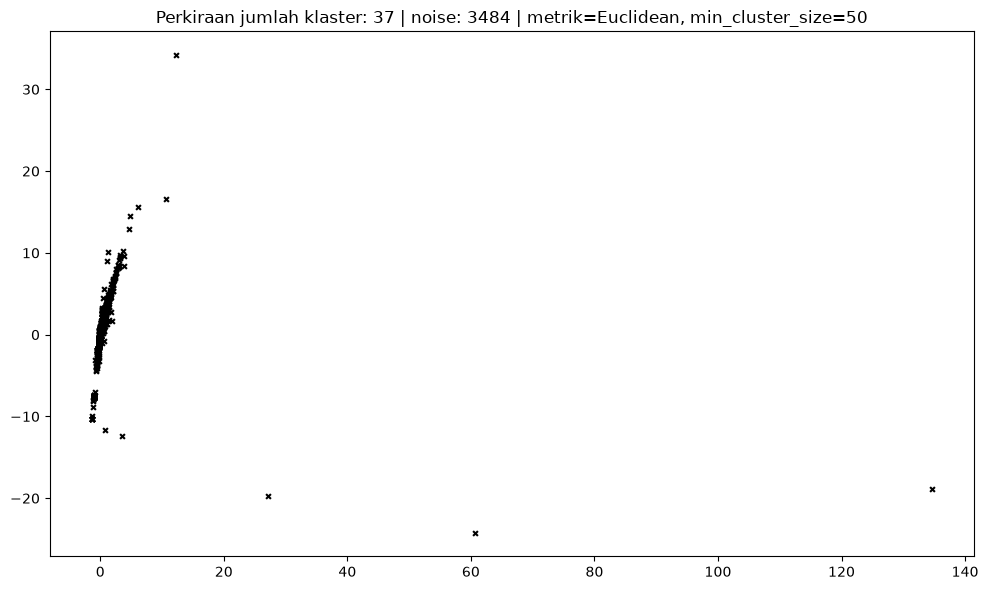

In [3]:
clusterer = hdbscan.HDBSCAN(metric="euclidean", min_cluster_size=50).fit(X)
alami = len(set(clusterer.labels_)) - (1 if -1 in clusterer.labels_ else 0)
print(f"Jumlah klaster alami: {alami}")
print(f"Noise alami: {int((clusterer.labels_ == -1).sum())} baris "
      f"({(clusterer.labels_ == -1).mean() * 100:.1f} %)")
fig, ax = plt.subplots(figsize=(10, 6))
plot(Y, clusterer.labels_, clusterer.probabilities_,
     parameters={"metrik": "Euclidean", "min_cluster_size": 50}, ax=ax)
plt.show()

**Membaca grafik jalan bebas.** Metrik Euclidean menemukan 37 cabang
kepadatan alami dengan 3484 noise (23) — struktur halus per
kota/kelas harga, bukan tiga kelompok besar. Fungsinya membuktikan tiga klaster
harus diambil lewat pemotongan hierarki.

## 4. Potong hierarki tepat 3 cabang (ketinggian lambda = 2,19)

Tinggi potong lambda = 2.19
Jumlah klaster final: 3
Noise akhir: 700 baris (4.7 %)
  klaster 0 (cabang 15006): 12884 titik
  klaster 1 (cabang 15001): 858 titik
  klaster 2 (cabang 15005): 558 titik


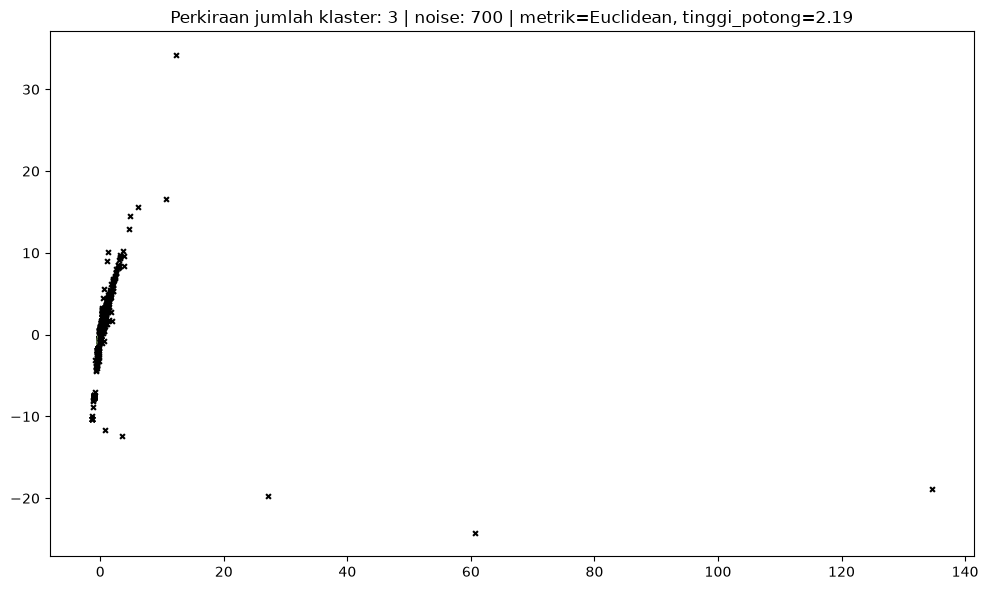

In [4]:
ROOT, lahir, anak, poin = parse_pohon(clusterer.condensed_tree_.to_pandas(), n)
TINGGI, labels3, sel, anggota = potong3(ROOT, lahir, anak, poin, n)
print(f"Tinggi potong lambda = {TINGGI:.2f}")
print("Jumlah klaster final: 3")
print(f"Noise akhir: {int((labels3 == -1).sum())} baris ({(labels3 == -1).mean() * 100:.1f} %)")
for i, c in enumerate(sel):
    print(f"  klaster {i} (cabang {c}): {len(anggota(c))} titik")
fig, ax = plt.subplots(figsize=(10, 6))
plot(Y, labels3, parameters={"metrik": "Euclidean", "tinggi_potong": round(TINGGI, 2)}, ax=ax)
plt.show()

**Membaca grafik potongan.** Pada ketinggian 2,19 pohon hanya
menyisakan tiga cabang: 12.884 + 858 + 558 titik terklaster dan 700 noise —
cakupan sekitar 95 persen. Perbandingan bentuk awan titik dengan
metrik lain ada di notebook `perbandingan_metrik`.

## 5. Profil tiga klaster (tabel penjelasan)

In [5]:
s["cluster"] = labels3
profil = s[s.cluster >= 0].groupby("cluster").agg(
    jumlah_baris=("harga", "size"),
    median_harga_rp=("harga", "median"),
    rata_luas_tanah_m2=("luas_m2", "mean"),
    rata_luas_bangunan_m2=("luas_bangunan", "mean"),
    rata_kamar=("jumlah_kamar", "mean"),
    rata_kamar_mandi=("jumlah_kamar_mandi", "mean"),
    pct_usia_terisi=("usia_bangunan", lambda x: (x > 0).mean() * 100),
).round(2)
profil["persen_baris"] = (profil["jumlah_baris"] / n * 100).round(1)
profil["median_harga_rp"] = profil["median_harga_rp"].map(lambda v: f"Rp {v:,.0f}")
print(profil.to_string())
print()
print("Lima lokasi terbanyak per klaster:")
for k in sorted(s[labels3 >= 0].cluster.unique()):
    top = s[labels3 == k]["lokasi"].value_counts().head(5)
    print(f"  klaster {k}: " + ", ".join(f"{nama} ({jml})" for nama, jml in top.items()))
if (labels3 == -1).sum():
    noise = s[labels3 == -1]
    print(f"Noise {len(noise)} baris | median harga Rp {noise['harga'].median():,.0f} "
          f"vs sampel Rp {s['harga'].median():,.0f}")


         jumlah_baris   median_harga_rp  rata_luas_tanah_m2  rata_luas_bangunan_m2  rata_kamar  rata_kamar_mandi  pct_usia_terisi  persen_baris
cluster                                                                                                                                        
0               12884    Rp 637,965,518              137.88                  85.69        2.46              1.67             6.74          85.9
1                 858  Rp 3,000,000,000              370.02                 287.14        5.20              3.93            15.50           5.7
2                 558  Rp 1,254,489,494              154.18                 148.78        0.00              1.51             1.61           3.7

Lima lokasi terbanyak per klaster:
  klaster 0: Kabupaten Bandung (475), Kabupaten Sidoarjo (448), Kabupaten Bekasi (433), Kabupaten Bogor (411), Bekasi (400)
  klaster 1: Surabaya (62), Bekasi (33), Jakarta Selatan (30), Kabupaten Tangerang (30), Medan (23)
  klaster 2: Kabupat

Klaster 0 = pasar massal (median Rp 638 juta). Klaster 1 = premium
(Rp 3 miliar, tanah 370 m2, 5,2 kamar). Klaster 2 menarik perhatian: 558 baris
dengan rata-rata kamar = 0 — baris FLUS/Bekasi yang kolom kamarnya kosong
ditebus nilai 0. Ini artefak data, bukan jenis rumah; Euclidean cukup peka
membentuknya satu cabang karena kolom jumlah kamar & kamar mandi bernol
seragam.

## 6. Simpan hasil berlabel

In [6]:
kolom_simpan = ["sumber", "lokasi", "luas_m2", "luas_bangunan", "jumlah_kamar",
                "jumlah_kamar_mandi", "usia_bangunan", "harga", "log_harga", "cluster"]
s_out = s.copy()
s_out["cluster"] = labels3
s_out[kolom_simpan + ["cluster"]].to_csv("hasil_euclidean_15k.csv", index=False)
print("Tersimpan: hasil_euclidean_15k.csv | baris:", len(s_out))


Tersimpan: hasil_euclidean_15k.csv | baris: 15000
